In [35]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal
import math
from numba import cuda

In [36]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

# n_predata = 50
# def gen_data():
#     X = nr.multivariate_normal(np.zeros(4), np.eye(4), n_predata)
#     y = np.zeros(n_predata)
#     for i in range(n_predata):
#         y[i] = nr.normal(X[i,2] + X[i,3], 2.5)
#     #write to file
#     df = pd.DataFrame(X)
#     df['y'] = y
#     df.to_csv('data.csv', index=False)
#     return X, y

# gen_data()

In [37]:
#read from file
def read_data():
    df = pd.read_csv('data.csv')
    X = df.values[:, 0:-1]
    y = df.values[:, -1]
    return X, y

L = [[0],[1],[2],[3],[0,1],[0,2],[0,3],[1,2],[1,3],[2,3],[0,1,2],[0,1,3],[0,2,3],[1,2,3],[0,1,2,3]]
names = []
for i in range(15):
    strs = ''
    inst = L[i]
    leni = len(inst)
    for j in range(leni):
        strs += str(inst[j]+1)
    strs = "x" + strs + '.npy'
    names.append(strs)
print(names)


['x1.npy', 'x2.npy', 'x3.npy', 'x4.npy', 'x12.npy', 'x13.npy', 'x14.npy', 'x23.npy', 'x24.npy', 'x34.npy', 'x123.npy', 'x124.npy', 'x134.npy', 'x234.npy', 'x1234.npy']


In [51]:
Truth = []
LiIMCV = []
LiCMC = []
VRFt = []
for i in range(15):
    print(names[i])
    input, output = read_data()
    input = input[:, L[i]]
    try: 
        input.shape[1]
    except:
        input = input[:,np.newaxis]
    dim = input.shape[1]
    N = input.shape[0]
    s = 2.5
    cov0 = np.linalg.inv(input.T @ input)

    def true_mean():
        const = (2*np.pi)**(-N/2)*s**(-N)*np.exp(-0.5*s**(-2)*np.sum(output**2))
        t = np.sum(output[:, np.newaxis]*input, axis=0)
        expcoef = 0.5*s**(-2)*(t.T @ cov0 @ t)
        def integrant(x):
            return const*np.exp(expcoef * x / (x+s**2)) *(1+x/s**2)**(-dim/2) * (1+x)**(-2)
        return scipy.integrate.quad(integrant, 0, np.inf)[0]

    tm = true_mean()
    Truth.append(tm)
    print(tm)
    nc = 4
    tar = gprior(dim)
    tar.set_parameters(cov0)
    pro = mix_normal(dim)
    a = tar.sampler(10000)
    try: 
        weights = np.load(names[i])[0]
        gs = np.load(names[i])[1]
        covs = np.array([gs[i]*cov0 for i in range(nc)])
    except:
        pro.em_algorithm(a,nc,cov0,3001)
        weights = pro.weights
        covs = pro.covs
        gs = pro.gs
        np.save(names[i], [weights, gs])

    Itrnum = 110
    sample_size = 100
    target = 'gprior'
    proposal = 'mix_normal'

    MyIM = IndMH(Itrnum, dim, target, proposal)
    MyIM.set_distribution_parameters(cov0, nc, weights, covs)
    est = BF(sample_size, weights, cov0, gs, input, output)
    estcmc = BF(sample_size, weights, cov0, gs, input, output)
    tar = gprior(dim)
    tar.set_parameters(cov0)

    epoch = 100
    cmc_mean = []
    imhcv_mean = []
    print("start")
    for i in range(epoch):
        data = MyIM.IMH()
        est.sample_loader(data[0],data[1],data[2])
        m,v= est.IMCV0()
        imhcv_mean.append(m)
        datacmc = tar.sampler(sample_size)
        estcmc.cmc_loader(datacmc)
        mc,vc = estcmc.CMC()
        # print(mc)
        # mc,vc = est.IM()
        cmc_mean.append(mc)

    var_imhcv = np.array(imhcv_mean).var()
    var_cmc = np.array(cmc_mean).var()
    print('VAR_IMCV:', var_imhcv)
    print('VAR_CMC:',var_cmc)
    print('STD_IMCV:', np.sqrt(var_imhcv))
    print('STD_CMC:', np.sqrt(var_cmc))
    mean_imhcv = np.array(imhcv_mean).mean()
    mean_cmc = np.array(cmc_mean).mean()
    error_imhcv = mean_imhcv - tm
    error_cmc = mean_cmc - tm
    print('True mean:',tm)
    print('IMCV:',mean_imhcv,'error:', np.abs(error_imhcv))
    mseimcv = var_imhcv + (error_imhcv)**2
    msecmc = var_cmc + (error_cmc)**2
    # print('MSEIMCV:',mseimcv)
    print('CMC:',mean_cmc, 'error:',np.abs(error_cmc))
    # print('MSECMC:',msecmc)
    LiIMCV.append(mean_imhcv)
    LiCMC.append(mean_cmc)
    VRFt.append(var_cmc/var_imhcv)
    print('VRF:',var_cmc/var_imhcv)

x1.npy
8.380122904873314e-52
8.360518150617299e-52
8.360518150617299e-52
start
VAR_IMCV: 1.2523761465071176e-106
VAR_CMC: 1.4723902787982768e-105
STD_IMCV: 1.1190961292521379e-53
STD_CMC: 3.8371738021599656e-53
True mean: 8.380122904873314e-52
IMCV: 8.363683208716431e-52 error: 1.643969615688274e-54
CMC: 8.397716118025027e-52 error: 1.759321315171316e-54
VRF: 11.756773577209845
x2.npy
7.73918527704616e-52
7.738948676459896e-52
7.738948676459896e-52
start
VAR_IMCV: 6.603940928782751e-135
VAR_CMC: 6.52798860915838e-106
STD_IMCV: 8.126463516673627e-68
STD_CMC: 2.5549928784946506e-53
True mean: 7.73918527704616e-52
IMCV: 7.738948676459895e-52 error: 2.3660058626496387e-56
CMC: 7.773046489745117e-52 error: 3.3861212698956826e-54
VRF: 9.884989401868605e+28
x3.npy
2.1294658409019878e-51
2.1526432133934105e-51
2.1526432133934105e-51
start
VAR_IMCV: 9.970285369634062e-105
VAR_CMC: 2.4165847095002543e-103
STD_IMCV: 9.985131631397787e-53
STD_CMC: 4.915877042299018e-52
True mean: 2.129465840901987

In [64]:
Truth = np.array(Truth)
LiIMCV = np.array(LiIMCV)
LiCMC = np.array(LiCMC)
VRFt = np.array(VRFt)
BF_truth = Truth / Truth[0]
BF_imcv = LiIMCV / LiIMCV[0]
BF_cmc = LiCMC / LiCMC[0]
print(Truth)
print(LiIMCV)
print(LiCMC)
print(VRFt)
print(BF_truth)
print(BF_imcv)
print(BF_cmc)
for i in range(15):
    print('$X_{', names[i][1:-4] ,'}$', '&',format(LiCMC[i],'.2e') , ' & ' , format(BF_cmc[i],'.2') , ' & ', format(LiIMCV[i],'.2e') , ' & ' , format(BF_imcv[i],'.2') , ' & ', np.round(VRFt[i],2) , ' & ' , format(Truth[i],'.2e'),' & ' , format(BF_truth[i],'.2') , '\\\\')

[8.38012290e-52 7.73918528e-52 2.12946584e-51 1.12100924e-51
 7.84975638e-52 2.38833290e-51 1.01365077e-51 1.70548129e-51
 1.07955874e-51 3.34771849e-51 1.91107775e-51 9.81733411e-52
 3.01388815e-51 2.79083415e-51 2.54011615e-51]
[8.36368321e-52 7.73894868e-52 2.31127058e-51 1.11059936e-51
 7.84630408e-52 2.63070803e-51 1.03029601e-51 1.82555740e-51
 1.10080673e-51 3.49435884e-51 2.04929611e-51 1.03290797e-51
 3.57025200e-51 2.97387496e-51 2.94185682e-51]
[8.39771612e-52 7.77304649e-52 2.19451320e-51 1.10612857e-51
 7.83736111e-52 2.41189222e-51 1.00455798e-51 1.75284413e-51
 1.08683483e-51 3.71156521e-51 1.93003555e-51 9.96446170e-52
 3.01284206e-51 2.64657604e-51 2.61340371e-51]
[ 11.75677358  99.          24.23786903  85.91610753  17.68958573
 471.53753247  10.75359342   9.36614619  33.09565438 260.49317839
 231.15537381  11.89640436  16.56449933 872.20857125 278.62348624]
[1.         0.92351692 2.54109142 1.33770024 0.93671137 2.84999746
 1.20958938 2.03515069 1.28823736 3.99483221

In [75]:

    # 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15
A = [[0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], #1
     [0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0], #2
     [0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0], #3
     [0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0], #4
     [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0], #5
     [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], #6
     [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0], #7
     [0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0], #8
     [0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0], #9
     [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0], #10
     [0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1], #11
     [0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1], #12
     [0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1], #13
     [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1], #14
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0]] #15



In [88]:
A = np.array(A)
transp = np.sum(A, axis=1)
choices = np.array([i for i in range(15)])
nitrs = 10000
init = 1
state = init
tar_state = LiIMCV[state]
pro_state = 1/transp[state]
states=[]
pmap = np.zeros((15,nitrs+1))
for i in range(nitrs):
    propoesed = np.random.choice(choices, p=A[state]/np.sum(A[state]))
    sample = np.random.uniform(0.0, 1.0, 1)
    ratio_tar = LiIMCV[propoesed]/tar_state
    ratio_pro = transp[propoesed]*pro_state
    ratio = min(1, ratio_tar*ratio_pro)
    if sample <= ratio:
        state = propoesed
        tar_state = LiIMCV[state]
        pro_state = 1/transp[state]
    pmap[:,i+1] = pmap[:,i]
    pmap[state,i+1] += 1
    states.append(state)

print(pmap[:,-1])
print


[ 160.  156.  444.  247.  268.  947.  369.  685.  409. 1419.  715.  383.
 1373. 1245. 1180.]


<Axes: >

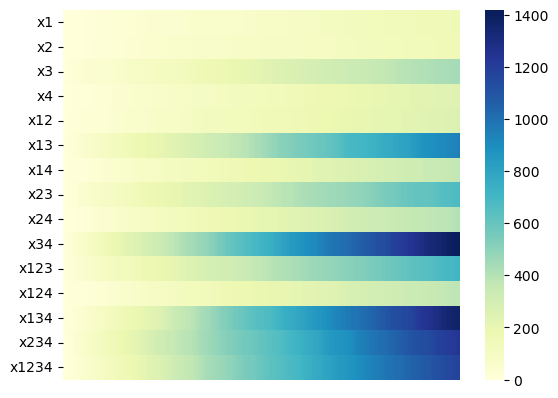

In [94]:
import seaborn as sns
names_new = [names[i][:-4] for i in range(15)]
sns.heatmap(pmap, cmap="YlGnBu", yticklabels=names_new, xticklabels=False)